# IGNITE H&E — Supervised vs Mean Teacher across labelled-data budgets (Google Colab)

This notebook runs a **label-budget comparison** for IGNITE v2 H&E tissue-compartment segmentation.

It compares:

- **Supervised segmentation:** uses only labelled H&E image/mask pairs.
- **Mean Teacher (semi-supervised):** uses the same labelled patients plus images from the remaining unlabelled training patients.

The primary comparison uses the exact 20%-labelled patient IDs and validation patient IDs stored in your completed Mean Teacher checkpoint. It also supports nested 10%, 20%, 50% and 100% labelled-patient experiments.

**Important terminology:** Mean Teacher is *semi-supervised learning*, not purely unsupervised learning. At 100% labelled data there is no unlabelled pool, so the notebook trains a supervised model only and marks Mean Teacher as not applicable.

## Recommended run order

1. Start with `EPOCHS = 10` and run the ratio sweep as a feasibility/pilot experiment.
2. Inspect the comparison table and class-wise results.
3. For a more substantial result, rerun the most relevant fractions (usually 20% and 50%) with `EPOCHS = 50` for **both** methods. The 20% Mean Teacher run can resume from its saved epoch-10 checkpoint.

The official test split is never used for training or model selection. All model selection and comparisons in this notebook use the same held-out validation patients.

## 1. Mount Google Drive, install dependencies, and check GPU

In [2]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA available:", torch.cuda.is_available())

GPU: Tesla T4
CUDA available: True


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

BASE_DIR = "/content/drive/MyDrive/IGNITE"

print(os.listdir(BASE_DIR))

['data_overview.csv', 'he_label_map.json', 'annotations.zip', 'annotations', 'IGNITE_H_and_E_Segmentation_Colab.ipynb', 'images', 'images.zip', 'training_outputs']


In [5]:
import os

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "training_outputs"
)

for root, dirs, files in os.walk(OUTPUT_DIR):
    for file in files:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

/content/drive/MyDrive/IGNITE/training_outputs/ignite_he_unet_resnet34/best_model.pth
/content/drive/MyDrive/IGNITE/training_outputs/ignite_he_unet_resnet34/last_checkpoint.pth
/content/drive/MyDrive/IGNITE/training_outputs/ignite_he_mean_teacher_20pct/last_checkpoint.pth
/content/drive/MyDrive/IGNITE/training_outputs/ignite_he_mean_teacher_20pct/best_teacher.pth


In [6]:
from google.colab import drive
drive.mount('/content/drive')

%pip -q install -U segmentation-models-pytorch scikit-learn pandas pillow tqdm matplotlib

from pathlib import Path
from functools import lru_cache
import os, json, math, random, shutil, gc, hashlib, time, copy
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('Enable a GPU in Colab: Runtime → Change runtime type → GPU.')
DEVICE = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0))
print(f'GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.6 GB


## 2. Configuration — start with the 10-epoch pilot

In [7]:
# Google Drive structure expected:
# MyDrive/IGNITE/images/he/
# MyDrive/IGNITE/annotations/he/
# MyDrive/IGNITE/data_overview.csv
# MyDrive/IGNITE/he_label_map.json

DRIVE_ROOT = Path('/content/drive/MyDrive/IGNITE')
DRIVE_IMAGES = DRIVE_ROOT / 'images' / 'he'
DRIVE_MASKS = DRIVE_ROOT / 'annotations' / 'he'
DRIVE_CSV = DRIVE_ROOT / 'data_overview.csv'
DRIVE_LABEL_MAP = DRIVE_ROOT / 'he_label_map.json'

# Existing Mean Teacher run from your previous notebook.
MT20_DIR = DRIVE_ROOT / 'training_outputs' / 'ignite_he_mean_teacher_20pct'
MT20_BEST = MT20_DIR / 'best_teacher.pth'
MT20_LAST = MT20_DIR / 'last_checkpoint.pth'

# All experiment outputs go here.
OUTPUT_ROOT = DRIVE_ROOT / 'training_outputs' / 'ignite_he_label_budget_comparison'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Pilot configuration. Use 10 epochs first. For a final longer experiment,
# change to 50 and rerun the selected fractions for BOTH methods.
EPOCHS = 10
LABEL_FRACTIONS = [0.10, 0.20, 0.50, 1.00]

PATCH_SIZE = 512
BATCH_SIZE = 2
NUM_CLASSES = 17       # pixel IDs 0..16
IGNORE_INDEX = 0       # ID 0 = Unannotated; ID 1 = actual Background
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
STEPS_PER_EPOCH = None # set after loading MT metadata; fixed across fractions
NUM_WORKERS = 0

# Mean Teacher settings — match the completed 20% experiment.
EMA_DECAY = 0.99
CONFIDENCE_THRESHOLD = 0.70
MAX_CONSISTENCY_WEIGHT = 0.5
CONSISTENCY_RAMPUP_EPOCHS = 5

SEED = 42
LABEL_SUBSET_SEED = 2026
USE_IMAGENET_NORMALIZATION = True

# Reuse the completed 20% Mean Teacher checkpoint at EPOCHS=10.
# If EPOCHS is raised above its saved epoch, resume it from last_checkpoint.pth.
REUSE_EXISTING_MT20 = True

# Set True only if you deliberately want to delete and retrain an experiment folder.
FORCE_RETRAIN = False

print('Data root:', DRIVE_ROOT)
print('Output root:', OUTPUT_ROOT)
print('Fractions:', LABEL_FRACTIONS)
print('Epochs:', EPOCHS)

Data root: /content/drive/MyDrive/IGNITE
Output root: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_label_budget_comparison
Fractions: [0.1, 0.2, 0.5, 1.0]
Epochs: 10


## 3. Check Drive folders and stage the H&E data to Colab local storage

In [8]:
required = [DRIVE_IMAGES, DRIVE_MASKS, DRIVE_CSV, DRIVE_LABEL_MAP, MT20_BEST]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError('Missing Drive items:\n' + '\n'.join(missing))

LOCAL_ROOT = Path('/content/ignite_ratio_sweep_data')
LOCAL_IMAGES = LOCAL_ROOT / 'images' / 'he'
LOCAL_MASKS = LOCAL_ROOT / 'annotations' / 'he'
LOCAL_CSV = LOCAL_ROOT / 'data_overview.csv'
LOCAL_LABEL_MAP = LOCAL_ROOT / 'he_label_map.json'
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

# Re-stage at the start of a fresh runtime. This avoids stale partial copies.
for p in [LOCAL_IMAGES, LOCAL_MASKS]:
    if p.exists():
        shutil.rmtree(p)
shutil.copytree(DRIVE_IMAGES, LOCAL_IMAGES)
shutil.copytree(DRIVE_MASKS, LOCAL_MASKS)
shutil.copy2(DRIVE_CSV, LOCAL_CSV)
shutil.copy2(DRIVE_LABEL_MAP, LOCAL_LABEL_MAP)

image_files = list(LOCAL_IMAGES.rglob('*.png'))
mask_files = list(LOCAL_MASKS.rglob('*.png'))
print(f'H&E images copied: {len(image_files)}')
print(f'H&E masks copied:  {len(mask_files)}')
if not image_files or not mask_files:
    raise FileNotFoundError('No PNGs found. Verify IGNITE/images/he and IGNITE/annotations/he.')

H&E images copied: 816
H&E masks copied:  816


## 4. Resolve the IGNITE H&E image-mask pairs

In [10]:
df_all = pd.read_csv(LOCAL_CSV)
required_cols = {'patient_id', 'name', 'task', 'image_path', 'annotation_path', 'split'}
missing_cols = required_cols - set(df_all.columns)
if missing_cols:
    raise ValueError(f'data_overview.csv is missing columns: {sorted(missing_cols)}')

he_source = df_all[df_all['task'].astype(str) == 'he_tissue_segmentation'].copy()
if he_source.empty:
    raise ValueError("No rows found for task='he_tissue_segmentation'.")

image_index = {p.name: p for p in LOCAL_IMAGES.rglob('*.png')}
mask_index = {p.name: p for p in LOCAL_MASKS.rglob('*.png')}

def basename_any(path_value):
    return str(path_value).replace('\\', '/').split('/')[-1]

def candidate_names(path_value):
    base = basename_any(path_value)
    stem = Path(base).stem
    if stem.endswith('_with_context'):
        return [base, stem[:-len('_with_context')] + '.png']
    return [stem + '_with_context.png', base]

resolved = []
missing_pairs = []
for row in he_source.to_dict('records'):
    img_candidates = candidate_names(row['image_path'])
    mask_candidates = candidate_names(row['annotation_path'])
    pair = None
    for iname, mname in zip(img_candidates, mask_candidates):
        if iname in image_index and mname in mask_index:
            pair = (image_index[iname], mask_index[mname], iname.endswith('_with_context.png'))
            break
    if pair is None:
        missing_pairs.append((row['name'], img_candidates, mask_candidates))
        continue
    row['patient_id'] = str(row['patient_id'])
    row['resolved_image'] = str(pair[0])
    row['resolved_mask'] = str(pair[1])
    row['used_context'] = bool(pair[2])
    resolved.append(row)

if missing_pairs:
    raise FileNotFoundError(f'{len(missing_pairs)} H&E pairs could not be resolved. Examples: {missing_pairs[:5]}')
he_df = pd.DataFrame(resolved).reset_index(drop=True)
print('Resolved H&E image-mask pairs:', len(he_df))
print('Context pairs:', int(he_df['used_context'].sum()))
print('Split counts:\n', he_df.groupby('split').size())

Resolved H&E image-mask pairs: 408
Context pairs: 408
Split counts:
 split
test     139
train    269
dtype: int64


## 5. Load label map and verify masks

In [11]:
with open(LOCAL_LABEL_MAP, 'r', encoding='utf-8') as f:
    label_map = json.load(f)
id_to_label = {int(v): k for k, v in label_map.items()}
if set(id_to_label) != set(range(NUM_CLASSES)):
    raise ValueError(f'Expected label IDs 0..16; found {sorted(id_to_label)}')

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def read_image_mask(image_path, mask_path):
    image = np.asarray(Image.open(image_path).convert('RGB'), dtype=np.uint8)
    mask = np.asarray(Image.open(mask_path))
    if mask.ndim == 3:
        if mask.shape[2] >= 3 and np.array_equal(mask[..., 0], mask[..., 1]) and np.array_equal(mask[..., 0], mask[..., 2]):
            mask = mask[..., 0]
        else:
            raise ValueError(f'Expected a single-channel integer mask: {mask_path}; got {mask.shape}')
    mask = mask.astype(np.uint8, copy=False)
    if image.shape[:2] != mask.shape:
        raise ValueError(f'Image/mask dimensions differ: {Path(image_path).name} {image.shape[:2]} vs {mask.shape}')
    ids = np.unique(mask)
    if np.any(ids >= NUM_CLASSES):
        raise ValueError(f'Unexpected label IDs {ids.tolist()} in {mask_path}')
    return image, mask

print('Label IDs:')
for i in range(NUM_CLASSES):
    print(f'{i:2d}: {id_to_label[i]}')

for _, r in he_df.sample(min(5, len(he_df)), random_state=SEED).iterrows():
    im, mk = read_image_mask(r['resolved_image'], r['resolved_mask'])
    print(r['name'], im.shape, mk.shape, 'IDs:', np.unique(mk).tolist())

Label IDs:
 0: Unannotated
 1: Background
 2: Tumor epithelium
 3: Reactive epithelium
 4: Stroma
 5: Inflammation
 6: Alveolar tissue
 7: Fatty tissue
 8: Necrotic tissue
 9: Erythrocytes
10: Bronchial epithelium
11: Mucus/Plasma/Fluids
12: Cartilage/Bone
13: Macrophages
14: Muscle
15: Liver
16: Keratinization
patient21_he_roi2 (1536, 1792, 3) (1536, 1792) IDs: [0, 1, 4, 9]
patient56_he_roi3 (2560, 2560, 3) (2560, 2560) IDs: [0, 1, 2, 4, 8, 9, 13]
patient66_he_roi4 (3072, 1792, 3) (3072, 1792) IDs: [0, 1, 3, 4, 5, 6, 9, 11, 13]
patient9_he_roi1 (1792, 1792, 3) (1792, 1792) IDs: [0, 1, 2, 4, 8, 9]
patient12_he_roi1 (1792, 1792, 3) (1792, 1792) IDs: [0, 1, 2, 4, 6, 8, 9, 13]


## 6. Reconstruct the exact training and validation patients from the Mean Teacher checkpoint

In [13]:

# Load existing Mean Teacher checkpoint
mt20_best_ckpt = torch.load(
    MT20_BEST,
    map_location="cpu",
    weights_only=False
)

# Validate essential checkpoint metadata
required_meta = [
    "model_state_dict",
    "labeled_patient_ids",
    "validation_patient_ids",
    "patch_size"
]

missing_meta = [
    k for k in required_meta
    if k not in mt20_best_ckpt
]

if missing_meta:
    raise KeyError(
        f"Missing essential checkpoint metadata: {missing_meta}"
    )

# Normalize patient IDs to strings
he_df["patient_id"] = he_df["patient_id"].astype(str)

# Restore labelled and validation patient IDs
base_labeled_ids = set(
    map(str, mt20_best_ckpt["labeled_patient_ids"])
)

validation_ids = set(
    map(str, mt20_best_ckpt["validation_patient_ids"])
)

# Reconstruct the original training patient pool
train_pool_ids = set(
    he_df.loc[
        he_df["split"].astype(str).str.lower() == "train",
        "patient_id"
    ]
)

# Exclude validation patients from training
train_ids = train_pool_ids - validation_ids

# Reconstruct unlabelled patients dynamically
base_unlabeled_ids = train_ids - base_labeled_ids

# Verify the reconstructed split
assert base_labeled_ids.issubset(train_ids)
assert not (base_labeled_ids & base_unlabeled_ids)
assert not (train_ids & validation_ids)

print("Checkpoint metadata restored successfully!")
print("Total training patients:", len(train_ids))
print("Labelled patients:", len(base_labeled_ids))
print("Unlabelled patients:", len(base_unlabeled_ids))
print("Validation patients:", len(validation_ids))
print(
    "Actual labelled percentage:",
    f"{len(base_labeled_ids)/len(train_ids)*100:.2f}%"
)

# Verify patch size
assert int(mt20_best_ckpt["patch_size"]) == PATCH_SIZE

print("Patch size:", PATCH_SIZE)
print("Mean Teacher checkpoint:", MT20_BEST)

train_df = he_df[(he_df['split'].astype(str).str.lower() == 'train') & he_df['patient_id'].isin(train_ids)].copy().reset_index(drop=True)
val_df = he_df[(he_df['split'].astype(str).str.lower() == 'train') & he_df['patient_id'].isin(validation_ids)].copy().reset_index(drop=True)
test_df = he_df[he_df['split'].astype(str).str.lower() == 'test'].copy().reset_index(drop=True)

if set(train_df['patient_id']) != train_ids:
    raise ValueError(f'Training patient IDs reconstructed from CSV do not match checkpoint. Missing: {sorted(train_ids - set(train_df.patient_id))}')
if set(val_df['patient_id']) != validation_ids:
    raise ValueError(f'Validation patient IDs reconstructed from CSV do not match checkpoint. Missing: {sorted(validation_ids - set(val_df.patient_id))}')
if train_ids & validation_ids:
    raise RuntimeError('Patient leakage between training and validation.')
if set(test_df['patient_id']) & (train_ids | validation_ids):
    raise RuntimeError('Official test patients overlap with training/validation patients.')
if int(mt20_best_ckpt['patch_size']) != PATCH_SIZE:
    raise ValueError(f'Patch size mismatch: checkpoint={mt20_best_ckpt["patch_size"]}, notebook={PATCH_SIZE}')

print(f'Training ROIs/patients: {len(train_df)} / {len(train_ids)}')
print(f'Validation ROIs/patients: {len(val_df)} / {len(validation_ids)}')
print(f'Official test ROIs: {len(test_df)} (not used)')
print(f'Existing 20% Mean Teacher epoch: {mt20_best_ckpt.get("epoch", "unknown")}')
print(f'Existing 20% selected labelled patients: {len(base_labeled_ids)} / {len(train_ids)} = {len(base_labeled_ids)/len(train_ids):.1%}')
print('Existing 20% validation patient IDs exactly restored.')

# Use the same update count as the original 20%-labelled Mean Teacher run.
# It was derived from the 186 unlabelled ROIs / batch size 2 = 93 updates per epoch.
STEPS_PER_EPOCH = min(math.ceil(len(train_df[train_df.patient_id.isin(base_unlabeled_ids)]) / BATCH_SIZE), 100)
print('Fixed optimizer updates per epoch for every ratio:', STEPS_PER_EPOCH)

# Construct nested labelled-patient subsets. The 20% entry is EXACTLY the original
# Mean Teacher patient set; 10% is a subset of it; 50% adds patients; 100% is all.
rng = np.random.default_rng(LABEL_SUBSET_SEED)
base_order = sorted(base_labeled_ids)
rng.shuffle(base_order)
remaining_order = sorted(base_unlabeled_ids)
rng.shuffle(remaining_order)

fraction_to_ids = {}
for frac in LABEL_FRACTIONS:
    if frac <= 0 or frac > 1:
        raise ValueError(f'Invalid labelled fraction {frac}; use values in (0, 1].')
    target_n = max(1, int(round(frac * len(train_ids))))
    if abs(frac - 0.20) < 1e-9:
        chosen = set(base_labeled_ids)  # preserve the exact existing 20% MT split
    elif frac < 0.20:
        chosen = set(base_order[:target_n])
    elif frac < 1.0:
        chosen = set(base_labeled_ids)
        chosen.update(remaining_order[:max(0, target_n - len(chosen))])
    else:
        chosen = set(train_ids)
    fraction_to_ids[frac] = chosen

subset_rows = []
for frac, chosen in fraction_to_ids.items():
    chosen_rois = train_df[train_df.patient_id.isin(chosen)]
    subset_rows.append({
        'nominal_label_fraction': frac,
        'labelled_patients': len(chosen),
        'total_training_patients': len(train_ids),
        'actual_patient_fraction': len(chosen)/len(train_ids),
        'labelled_ROIs': len(chosen_rois),
        'unlabelled_patients': len(train_ids)-len(chosen),
        'unlabelled_ROIs': len(train_df)-len(chosen_rois),
    })
subset_summary = pd.DataFrame(subset_rows).sort_values('nominal_label_fraction')
display(subset_summary)
subset_summary.to_csv(OUTPUT_ROOT / 'label_budget_split_summary.csv', index=False)

# Save all patient IDs for reproducibility and reporting.
split_manifest = {
    'training_patient_ids': sorted(train_ids),
    'validation_patient_ids': sorted(validation_ids),
    'official_test_patient_ids_not_used': sorted(set(test_df.patient_id)),
    'labelled_patient_ids_by_fraction': {str(k): sorted(v) for k, v in fraction_to_ids.items()},
    'seed_for_nested_subsets': LABEL_SUBSET_SEED,
}
with open(OUTPUT_ROOT / 'split_manifest.json', 'w') as f:
    json.dump(split_manifest, f, indent=2)


Checkpoint metadata restored successfully!
Total training patients: 38
Labelled patients: 7
Unlabelled patients: 31
Validation patients: 10
Actual labelled percentage: 18.42%
Patch size: 512
Mean Teacher checkpoint: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_mean_teacher_20pct/best_teacher.pth
Training ROIs/patients: 218 / 38
Validation ROIs/patients: 51 / 10
Official test ROIs: 139 (not used)
Existing 20% Mean Teacher epoch: 10
Existing 20% selected labelled patients: 7 / 38 = 18.4%
Existing 20% validation patient IDs exactly restored.
Fixed optimizer updates per epoch for every ratio: 93


,nominal_label_fraction,labelled_patients,total_training_patients,actual_patient_fraction,labelled_ROIs,unlabelled_patients,unlabelled_ROIs
0,0.1,4,38,0.105263,21,34,197
1,0.2,7,38,0.184211,32,31,186
2,0.5,19,38,0.500000,96,19,122
3,1.0,38,38,1.000000,218,0,0


## 7. Image patch datasets and augmentation

In [14]:
from torch.utils.data import Dataset, DataLoader

@lru_cache(maxsize=8)
def cached_image(image_path):
    return np.asarray(Image.open(image_path).convert('RGB'), dtype=np.uint8)

@lru_cache(maxsize=8)
def cached_pair(image_path, mask_path):
    image, mask = read_image_mask(image_path, mask_path)
    coords = np.argwhere(mask > IGNORE_INDEX)
    if len(coords) > 50000:
        stable = hashlib.sha1((image_path + mask_path).encode()).hexdigest()
        seed = int(stable[:8], 16)
        rng_local = np.random.default_rng(seed)
        coords = coords[rng_local.choice(len(coords), size=50000, replace=False)]
    return image, mask, coords

def pad_image(image, patch_size):
    h, w = image.shape[:2]
    ph, pw = max(0, patch_size-h), max(0, patch_size-w)
    if ph or pw:
        mode = 'reflect' if h > 1 and w > 1 else 'edge'
        image = np.pad(image, ((0,ph),(0,pw),(0,0)), mode=mode)
    return image

def pad_image_mask(image, mask, patch_size):
    h, w = mask.shape
    ph, pw = max(0, patch_size-h), max(0, patch_size-w)
    if ph or pw:
        mode = 'reflect' if h > 1 and w > 1 else 'edge'
        image = np.pad(image, ((0,ph),(0,pw),(0,0)), mode=mode)
        mask = np.pad(mask, ((0,ph),(0,pw)), mode='constant', constant_values=IGNORE_INDEX)
    return image, mask

def crop_location(image, patch_size, coords=None):
    h, w = image.shape[:2]
    if coords is not None and len(coords):
        cy, cx = coords[random.randrange(len(coords))]
        top = min(max(int(cy)-patch_size//2, 0), h-patch_size)
        left = min(max(int(cx)-patch_size//2, 0), w-patch_size)
    else:
        top = random.randint(0, max(0, h-patch_size))
        left = random.randint(0, max(0, w-patch_size))
    return top, left

def geometric_augment(image, mask=None):
    if random.random() < 0.5:
        image = np.fliplr(image)
        if mask is not None: mask = np.fliplr(mask)
    if random.random() < 0.5:
        image = np.flipud(image)
        if mask is not None: mask = np.flipud(mask)
    k = random.randrange(4)
    if k:
        image = np.rot90(image, k)
        if mask is not None: mask = np.rot90(mask, k)
    if mask is None:
        return np.ascontiguousarray(image)
    return np.ascontiguousarray(image), np.ascontiguousarray(mask)

def strong_colour_augment(image):
    x = image.astype(np.float32)
    if random.random() < 0.8:
        x *= random.uniform(0.85, 1.15)
    if random.random() < 0.8:
        contrast = random.uniform(0.85, 1.15)
        mean = x.mean(axis=(0,1), keepdims=True)
        x = (x-mean)*contrast + mean
    if random.random() < 0.5:
        gray = x.mean(axis=2, keepdims=True)
        x = (x-gray)*random.uniform(0.85,1.15) + gray
    if random.random() < 0.2:
        x += np.random.normal(0, 2.0, size=x.shape).astype(np.float32)
    return np.clip(x, 0, 255).astype(np.uint8)

def image_to_tensor(image):
    x = image.astype(np.float32) / 255.0
    if USE_IMAGENET_NORMALIZATION:
        x = (x-IMAGENET_MEAN)/IMAGENET_STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2,0,1))).float()

class LabelledPatchDataset(Dataset):
    def __init__(self, records, patch_size=512, patches_per_roi=1):
        self.records, self.patch_size, self.patches_per_roi = records, patch_size, patches_per_roi
    def __len__(self):
        return len(self.records) * self.patches_per_roi
    def __getitem__(self, index):
        row = self.records[index // self.patches_per_roi]
        image, mask, coords = cached_pair(row['resolved_image'], row['resolved_mask'])
        image, mask = pad_image_mask(image, mask, self.patch_size)
        top, left = crop_location(image, self.patch_size, coords)
        ip = image[top:top+self.patch_size, left:left+self.patch_size].copy()
        mp = mask[top:top+self.patch_size, left:left+self.patch_size].copy()
        ip, mp = geometric_augment(ip, mp)
        return image_to_tensor(ip), torch.from_numpy(mp.copy()).long()

class UnlabelledPatchDataset(Dataset):
    def __init__(self, records, patch_size=512, patches_per_roi=1):
        self.records, self.patch_size, self.patches_per_roi = records, patch_size, patches_per_roi
    def __len__(self):
        return len(self.records) * self.patches_per_roi
    def __getitem__(self, index):
        row = self.records[index // self.patches_per_roi]
        # Crucial: only load the image; do NOT open its annotation mask.
        image = pad_image(cached_image(row['resolved_image']), self.patch_size)
        top, left = crop_location(image, self.patch_size, None)
        ip = image[top:top+self.patch_size, left:left+self.patch_size].copy()
        weak = geometric_augment(ip)
        strong = strong_colour_augment(weak.copy())
        return image_to_tensor(weak), image_to_tensor(strong)

print('Patch datasets ready.')

Patch datasets ready.


## 8. Model, validation metrics, and utility functions

In [15]:
def experiment_seed(fraction):
    # The original 20% Mean Teacher checkpoint was initialized with SEED=42.
    # Keep that exact seed for the 20% supervised control; use matched seeds for
    # each other ratio's supervised and Mean Teacher pair.
    return SEED if abs(fraction-0.20) < 1e-9 else SEED + int(round(fraction*1000))

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(pretrained=True):
    return smp.Unet(
        encoder_name='resnet34', encoder_weights='imagenet' if pretrained else None,
        in_channels=3, classes=NUM_CLASSES, activation=None
    )

criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
scaler_enabled = DEVICE.type == 'cuda'

def autocast_context():
    return torch.amp.autocast(device_type='cuda', enabled=scaler_enabled)

def make_loader(dataset, shuffle=True):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)

def next_cyclic(iterator, loader):
    try:
        batch = next(iterator)
    except StopIteration:
        iterator = iter(loader)
        batch = next(iterator)
    return batch, iterator

@torch.inference_mode()
def evaluate_model(model, records, desc='Validation'):
    model.eval()
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for row in tqdm(records, desc=desc, leave=False):
        image, mask, _ = cached_pair(row['resolved_image'], row['resolved_mask'])
        h, w = mask.shape
        ph = (PATCH_SIZE - h % PATCH_SIZE) % PATCH_SIZE
        pw = (PATCH_SIZE - w % PATCH_SIZE) % PATCH_SIZE
        if ph or pw:
            mode = 'reflect' if h > 1 and w > 1 else 'edge'
            image_eval = np.pad(image, ((0,ph),(0,pw),(0,0)), mode=mode)
            mask_eval = np.pad(mask, ((0,ph),(0,pw)), mode='constant', constant_values=IGNORE_INDEX)
        else:
            image_eval, mask_eval = image, mask
        H, W = mask_eval.shape
        for top in range(0, H, PATCH_SIZE):
            for left in range(0, W, PATCH_SIZE):
                ip = image_eval[top:top+PATCH_SIZE, left:left+PATCH_SIZE]
                mp = mask_eval[top:top+PATCH_SIZE, left:left+PATCH_SIZE]
                x = image_to_tensor(ip).unsqueeze(0).to(DEVICE, non_blocking=True)
                with autocast_context():
                    logits = model(x)
                pred = logits.argmax(1)[0].cpu().numpy().astype(np.uint8)
                valid = mp > IGNORE_INDEX  # ignore unannotated ground-truth ID 0
                if valid.any():
                    encoded = mp[valid].astype(np.int64)*NUM_CLASSES + pred[valid].astype(np.int64)
                    cm += np.bincount(encoded, minlength=NUM_CLASSES*NUM_CLASSES).reshape(NUM_CLASSES, NUM_CLASSES)

    per_class = {}
    dice_all, dice_fg, iou_fg = [], [], []
    for cid in range(1, NUM_CLASSES):
        tp = cm[cid,cid]
        fp = cm[:,cid].sum()-tp
        fn = cm[cid,:].sum()-tp
        dden = 2*tp+fp+fn
        iden = tp+fp+fn
        dice = float(2*tp/dden) if dden else float('nan')
        iou = float(tp/iden) if iden else float('nan')
        per_class[cid] = {'class_name': id_to_label[cid], 'dice': dice, 'iou': iou,
                          'ground_truth_pixels': int(cm[cid,:].sum())}
        if np.isfinite(dice):
            dice_all.append(dice)
            if cid >= 2: dice_fg.append(dice)
        if cid >= 2 and np.isfinite(iou): iou_fg.append(iou)
    metrics = {
        'mean_dice_all_annotated': float(np.mean(dice_all)) if dice_all else float('nan'),
        'mean_dice_foreground': float(np.mean(dice_fg)) if dice_fg else float('nan'),
        'mean_iou_foreground': float(np.mean(iou_fg)) if iou_fg else float('nan'),
        'foreground_classes_with_defined_dice': len(dice_fg),
    }
    return metrics, per_class, cm

print('Model/evaluation functions ready.')

Model/evaluation functions ready.


## 9. Training functions — supervised and Mean Teacher

In [16]:
def consistency_weight(epoch):
    progress = min(1.0, float(epoch) / max(1, CONSISTENCY_RAMPUP_EPOCHS))
    ramp = math.exp(-5.0 * (1.0-progress)**2)
    return MAX_CONSISTENCY_WEIGHT * ramp

@torch.no_grad()
def update_teacher(student, teacher, global_step):
    # Bias-corrected early EMA, same update convention as the completed MT run.
    alpha = min(EMA_DECAY, 1.0 - 1.0/float(global_step+1))
    for t_param, s_param in zip(teacher.parameters(), student.parameters()):
        t_param.data.mul_(alpha).add_(s_param.data, alpha=1.0-alpha)
    # Copy BatchNorm running statistics and counters.
    for t_buffer, s_buffer in zip(teacher.buffers(), student.buffers()):
        t_buffer.copy_(s_buffer)
    return alpha

def checkpoint_matches(path, labelled_ids):
    if not path.exists():
        return False
    ck = torch.load(path, map_location='cpu', weights_only=False)
    return (set(map(str, ck.get('labeled_patient_ids', []))) == set(map(str, labelled_ids)) and
            set(map(str, ck.get('validation_patient_ids', []))) == validation_ids)

def train_supervised(labelled_records, labelled_ids, fraction, run_dir, epochs):
    run_dir.mkdir(parents=True, exist_ok=True)
    best_path, last_path = run_dir/'best_supervised.pth', run_dir/'last_supervised.pth'
    history_path = run_dir/'supervised_history.csv'
    if FORCE_RETRAIN:
        for p in [best_path, last_path, history_path]:
            if p.exists(): p.unlink()

    set_seed(experiment_seed(fraction))
    model = build_model(pretrained=True).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    scaler = torch.amp.GradScaler('cuda', enabled=scaler_enabled)
    best_score, start_epoch, history = -1.0, 1, []

    if last_path.exists() and not FORCE_RETRAIN:
        ck = torch.load(last_path, map_location='cpu', weights_only=False)
        if set(map(str, ck.get('labeled_patient_ids', []))) != set(map(str, labelled_ids)) or set(map(str, ck.get('validation_patient_ids', []))) != validation_ids:
            raise ValueError(f'Existing supervised checkpoint split mismatch in {last_path}. Set FORCE_RETRAIN=True.')
        if int(ck.get('epoch', 0)) >= epochs and best_path.exists():
            print(f'Reusing completed supervised run: {best_path}')
            return best_path
        model.load_state_dict(ck['model_state_dict'])
        optimizer.load_state_dict(ck['optimizer_state_dict'])
        scheduler.load_state_dict(ck['scheduler_state_dict'])
        scaler.load_state_dict(ck['scaler_state_dict'])
        start_epoch = int(ck['epoch']) + 1
        best_score = float(ck.get('best_val_dice', -1.0))
        history = ck.get('history', [])
        print('Resuming supervised model at epoch', start_epoch)

    dataset = LabelledPatchDataset(labelled_records, PATCH_SIZE, patches_per_roi=1)
    loader = make_loader(dataset, shuffle=True)
    for epoch in range(start_epoch, epochs+1):
        model.train()
        iterator = iter(loader)
        losses = []
        progress = tqdm(range(STEPS_PER_EPOCH), desc=f'Supervised {fraction:.0%} epoch {epoch}/{epochs}')
        for _ in progress:
            (x,y), iterator = next_cyclic(iterator, loader)
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            if not torch.any(y != IGNORE_INDEX):
                continue
            optimizer.zero_grad(set_to_none=True)
            with autocast_context():
                logits = model(x)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            scaler.step(optimizer); scaler.update()
            losses.append(float(loss.detach().cpu()))

        val_metrics, _, _ = evaluate_model(model, val_records, desc=f'Supervised {fraction:.0%} validation')
        val_score = val_metrics['mean_dice_foreground']
        scheduler.step(val_score)
        row = {'epoch': epoch, 'train_loss': float(np.mean(losses)) if losses else float('nan'),
               **val_metrics, 'learning_rate': optimizer.param_groups[0]['lr']}
        history.append(row)
        pd.DataFrame(history).to_csv(history_path, index=False)
        payload = {'epoch': epoch, 'model_state_dict': model.state_dict(),
                   'optimizer_state_dict': optimizer.state_dict(), 'scheduler_state_dict': scheduler.state_dict(),
                   'scaler_state_dict': scaler.state_dict(), 'best_val_dice': max(best_score, val_score),
                   'history': history, 'labeled_patient_ids': sorted(map(str,labelled_ids)),
                   'validation_patient_ids': sorted(validation_ids), 'label_fraction_nominal': fraction,
                   'patch_size': PATCH_SIZE, 'num_classes': NUM_CLASSES, 'ignore_index': IGNORE_INDEX}
        tmp = Path('/content/last_supervised_tmp.pth'); torch.save(payload, tmp); shutil.copy2(tmp, last_path)
        if np.isfinite(val_score) and val_score > best_score:
            best_score = val_score
            tmp = Path('/content/best_supervised_tmp.pth'); torch.save(payload, tmp); shutil.copy2(tmp, best_path)
        print(f'epoch {epoch}: loss={row["train_loss"]:.4f} | val foreground Dice={val_score:.4f} | best={best_score:.4f}')
    return best_path

def train_mean_teacher(labelled_records, unlabelled_records, labelled_ids, fraction, run_dir, epochs, resume_path=None):
    if not unlabelled_records:
        raise ValueError('Mean Teacher requires an unlabelled training pool; skip it at 100% labelled data.')
    run_dir.mkdir(parents=True, exist_ok=True)
    best_path, last_path = run_dir/'best_mean_teacher.pth', run_dir/'last_mean_teacher.pth'
    history_path = run_dir/'mean_teacher_history.csv'
    if FORCE_RETRAIN:
        for p in [best_path, last_path, history_path]:
            if p.exists(): p.unlink()

    set_seed(experiment_seed(fraction))
    student = build_model(pretrained=True).to(DEVICE)
    teacher = build_model(pretrained=False).to(DEVICE)
    teacher.load_state_dict(student.state_dict())
    teacher.eval()
    for p in teacher.parameters(): p.requires_grad_(False)
    optimizer = torch.optim.AdamW(student.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    scaler = torch.amp.GradScaler('cuda', enabled=scaler_enabled)
    start_epoch, global_step, best_score, history = 1, 0, -1.0, []

    # Resume support for runs already started in this notebook, or for the original 20% MT run.
    source_resume = None if FORCE_RETRAIN else (last_path if last_path.exists() else (resume_path if resume_path and Path(resume_path).exists() else None))
    if source_resume and not FORCE_RETRAIN:
        ck = torch.load(source_resume, map_location='cpu', weights_only=False)
        saved_ids = set(map(str, ck.get('labeled_patient_ids', [])))
        saved_val = set(map(str, ck.get('validation_patient_ids', [])))
        if saved_ids != set(map(str,labelled_ids)) or saved_val != validation_ids:
            raise ValueError(f'Mean Teacher resume checkpoint has a different patient split: {source_resume}')
        student.load_state_dict(ck['student_state_dict'])
        teacher.load_state_dict(ck['teacher_state_dict'])
        optimizer.load_state_dict(ck['optimizer_state_dict'])
        scheduler.load_state_dict(ck['scheduler_state_dict'])
        scaler.load_state_dict(ck['scaler_state_dict'])
        start_epoch = int(ck['epoch']) + 1
        global_step = int(ck.get('global_step', 0))
        best_score = float(ck.get('best_val_dice', -1.0))
        history = ck.get('history', [])
        # If resuming the original 20% run into a new ratio-sweep folder, preserve
        # the already-best teacher from epoch 1..N before continuing.
        if resume_path and Path(resume_path).resolve() == MT20_LAST.resolve() and not best_path.exists() and MT20_BEST.exists():
            shutil.copy2(MT20_BEST, best_path)
        print(f'Resuming Mean Teacher from {source_resume}; next epoch={start_epoch}')
    elif best_path.exists() and not FORCE_RETRAIN:
        ck = torch.load(best_path, map_location='cpu', weights_only=False)
        if set(map(str, ck.get('labeled_patient_ids', []))) == set(map(str,labelled_ids)) and set(map(str, ck.get('validation_patient_ids', []))) == validation_ids and int(ck.get('epoch',0)) >= epochs:
            print('Reusing completed Mean Teacher run:', best_path)
            return best_path

    l_loader = make_loader(LabelledPatchDataset(labelled_records, PATCH_SIZE, 1), shuffle=True)
    u_loader = make_loader(UnlabelledPatchDataset(unlabelled_records, PATCH_SIZE, 1), shuffle=True)
    for epoch in range(start_epoch, epochs+1):
        student.train(); teacher.eval()
        l_iter, u_iter = iter(l_loader), iter(u_loader)
        sup_losses, cons_losses, coverages = [], [], []
        lambda_u = consistency_weight(epoch)
        progress = tqdm(range(STEPS_PER_EPOCH), desc=f'Mean Teacher {fraction:.0%} epoch {epoch}/{epochs}')
        for _ in progress:
            (x_l,y_l), l_iter = next_cyclic(l_iter, l_loader)
            (x_weak,x_strong), u_iter = next_cyclic(u_iter, u_loader)
            x_l, y_l = x_l.to(DEVICE, non_blocking=True), y_l.to(DEVICE, non_blocking=True)
            x_weak = x_weak.to(DEVICE, non_blocking=True)
            x_strong = x_strong.to(DEVICE, non_blocking=True)
            if not torch.any(y_l != IGNORE_INDEX):
                continue
            optimizer.zero_grad(set_to_none=True)
            x_student = torch.cat([x_l, x_strong], dim=0)
            with autocast_context():
                logits_all = student(x_student)
                logits_l = logits_all[:x_l.shape[0]]
                logits_u_student = logits_all[x_l.shape[0]:]
                loss_sup = criterion(logits_l, y_l)
            with torch.no_grad():
                with autocast_context():
                    logits_u_teacher = teacher(x_weak)
                probs_teacher = torch.softmax(logits_u_teacher.float(), dim=1)
                confidence, predicted = probs_teacher.max(dim=1)
                valid_pseudo = (confidence >= CONFIDENCE_THRESHOLD) & (predicted != IGNORE_INDEX)
            probs_student = torch.softmax(logits_u_student.float(), dim=1)
            per_pixel = (probs_student - probs_teacher.detach()).pow(2).mean(dim=1)
            loss_cons = per_pixel[valid_pseudo].mean() if valid_pseudo.any() else per_pixel.sum()*0.0
            loss_total = loss_sup + lambda_u*loss_cons
            if not torch.isfinite(loss_total):
                raise RuntimeError('Non-finite Mean Teacher loss.')
            scaler.scale(loss_total).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(student.parameters(), max_norm=5.0)
            scaler.step(optimizer); scaler.update()
            global_step += 1
            update_teacher(student, teacher, global_step)
            sup_losses.append(float(loss_sup.detach().cpu()))
            cons_losses.append(float(loss_cons.detach().cpu()))
            coverages.append(float(valid_pseudo.float().mean().detach().cpu()))

        val_metrics, _, _ = evaluate_model(teacher, val_records, desc=f'Mean Teacher {fraction:.0%} validation')
        val_score = val_metrics['mean_dice_foreground']
        scheduler.step(val_score)
        row = {'epoch': epoch, 'supervised_loss': float(np.mean(sup_losses)) if sup_losses else float('nan'),
               'consistency_loss': float(np.mean(cons_losses)) if cons_losses else float('nan'),
               'consistency_weight': lambda_u, 'pseudo_label_coverage': float(np.mean(coverages)) if coverages else 0.0,
               **val_metrics, 'learning_rate': optimizer.param_groups[0]['lr']}
        history.append(row); pd.DataFrame(history).to_csv(history_path, index=False)
        payload = {'epoch': epoch, 'student_state_dict': student.state_dict(), 'teacher_state_dict': teacher.state_dict(),
                   'optimizer_state_dict': optimizer.state_dict(), 'scheduler_state_dict': scheduler.state_dict(),
                   'scaler_state_dict': scaler.state_dict(), 'global_step': global_step,
                   'best_val_dice': max(best_score,val_score), 'history': history,
                   'labeled_patient_ids': sorted(map(str,labelled_ids)),
                   'unlabeled_patient_ids': sorted(set(map(str,train_ids))-set(map(str,labelled_ids))),
                   'validation_patient_ids': sorted(validation_ids), 'label_fraction_nominal': fraction,
                   'confidence_threshold': CONFIDENCE_THRESHOLD, 'ema_decay': EMA_DECAY,
                   'patch_size': PATCH_SIZE, 'num_classes': NUM_CLASSES, 'ignore_index': IGNORE_INDEX}
        tmp = Path('/content/last_mt_tmp.pth'); torch.save(payload,tmp); shutil.copy2(tmp,last_path)
        if np.isfinite(val_score) and val_score > best_score:
            best_score = val_score
            best_payload = {'epoch': epoch, 'model_state_dict': teacher.state_dict(), 'val_metrics': val_metrics,
                            'labeled_patient_ids': sorted(map(str,labelled_ids)),
                            'validation_patient_ids': sorted(validation_ids), 'label_fraction_nominal': fraction,
                            'confidence_threshold': CONFIDENCE_THRESHOLD, 'ema_decay': EMA_DECAY,
                            'patch_size': PATCH_SIZE, 'num_classes': NUM_CLASSES, 'ignore_index': IGNORE_INDEX}
            tmp = Path('/content/best_mt_tmp.pth'); torch.save(best_payload,tmp); shutil.copy2(tmp,best_path)
        print(f'epoch {epoch}: supervised={row["supervised_loss"]:.4f} | consistency={row["consistency_loss"]:.5f} | pseudo coverage={row["pseudo_label_coverage"]:.1%} | val Dice={val_score:.4f}')
    return best_path

print('Training functions ready.')

Training functions ready.


## 10. Run the labelled-fraction experiments

In [18]:
results = []
class_results = []
trained_model_paths = {}

# Convert validation dataframe to records format for evaluation
val_records = val_df.to_dict('records')

# Reuse the original MT 20% run at 10 epochs. If EPOCHS > its saved last epoch,
# resume from the original last_checkpoint to keep the 20% MT experiment continuous.
original_mt_epoch = int(mt20_best_ckpt.get('epoch', 0))

for frac in LABEL_FRACTIONS:
    chosen_ids = fraction_to_ids[frac]
    labeled_df = train_df[train_df.patient_id.isin(chosen_ids)].copy().reset_index(drop=True)
    unlabeled_df = train_df[~train_df.patient_id.isin(chosen_ids)].copy().reset_index(drop=True)
    labeled_records = labeled_df.to_dict('records')
    unlabeled_records = unlabeled_df.to_dict('records')
    actual_frac = len(chosen_ids) / len(train_ids)
    frac_tag = f'{int(round(frac*100)):02d}pct'
    run_dir = OUTPUT_ROOT / frac_tag
    run_dir.mkdir(parents=True, exist_ok=True)

    print('\n' + '='*80)
    print(f'LABEL BUDGET {frac:.0%}: {len(chosen_ids)}/{len(train_ids)} patients ({actual_frac:.1%}); '
          f'{len(labeled_records)} labelled ROIs, {len(unlabeled_records)} unlabelled ROIs')
    print('='*80)

    # 1) Supervised model for this label budget.
    sup_dir = run_dir / 'supervised'
    sup_best = train_supervised(labeled_records, chosen_ids, frac, sup_dir, EPOCHS)
    trained_model_paths[(frac, 'supervised')] = sup_best
    sup_ckpt = torch.load(sup_best, map_location='cpu', weights_only=False)
    sup_model = build_model(pretrained=False).to(DEVICE)
    sup_model.load_state_dict(sup_ckpt['model_state_dict']); sup_model.eval()
    sup_metrics, sup_per_class, sup_cm = evaluate_model(sup_model, val_records, desc=f'Final supervised {frac:.0%}')
    results.append({'nominal_label_fraction': frac, 'actual_label_fraction': actual_frac,
                    'labelled_patients': len(chosen_ids), 'unlabelled_patients': len(train_ids)-len(chosen_ids),
                    'method': 'Supervised', 'best_epoch': int(sup_ckpt['epoch']), **sup_metrics})
    for cid, item in sup_per_class.items():
        class_results.append({'nominal_label_fraction': frac, 'method': 'Supervised', 'class_id': cid, **item})
    np.save(sup_dir/'validation_confusion_matrix.npy', sup_cm)
    del sup_model; gc.collect(); torch.cuda.empty_cache()

    # 2) Mean Teacher for this label budget. At 100% there is no unlabelled pool.
    if len(unlabeled_records) == 0:
        print('Mean Teacher: N/A — no unlabelled training patients at 100% labelled data.')
    else:
        mt_dir = run_dir / 'mean_teacher'
        mt_resume = None
        if abs(frac-0.20) < 1e-9 and REUSE_EXISTING_MT20 and not FORCE_RETRAIN:
            if EPOCHS <= original_mt_epoch:
                # The existing checkpoint is already trained to the requested epoch.
                mt_best_for_eval = MT20_BEST
                original_ck = torch.load(MT20_BEST, map_location='cpu', weights_only=False)
                if set(map(str, original_ck['labeled_patient_ids'])) != set(map(str, chosen_ids)):
                    raise ValueError('Existing 20% Mean Teacher model does not use the exact selected labelled IDs.')
                mt_dir.mkdir(parents=True, exist_ok=True)
                shutil.copy2(MT20_BEST, mt_dir/'best_mean_teacher.pth')
                mt_best = mt_dir/'best_mean_teacher.pth'
                print('Reusing existing 20% Mean Teacher teacher checkpoint from epoch', original_mt_epoch)
            else:
                if not MT20_LAST.exists():
                    raise FileNotFoundError('Cannot extend 20% Mean Teacher to more epochs: last_checkpoint.pth is missing.')
                mt_resume = MT20_LAST
                mt_best = train_mean_teacher(labeled_records, unlabeled_records, chosen_ids, frac, mt_dir, EPOCHS, resume_path=mt_resume)
        else:
            mt_best = train_mean_teacher(labeled_records, unlabeled_records, chosen_ids, frac, mt_dir, EPOCHS)
        trained_model_paths[(frac, 'mean_teacher')] = mt_best
        mt_ckpt = torch.load(mt_best, map_location='cpu', weights_only=False)
        mt_model = build_model(pretrained=False).to(DEVICE)
        mt_model.load_state_dict(mt_ckpt['model_state_dict']); mt_model.eval()
        mt_metrics, mt_per_class, mt_cm = evaluate_model(mt_model, val_records, desc=f'Final Mean Teacher {frac:.0%}')
        results.append({'nominal_label_fraction': frac, 'actual_label_fraction': actual_frac,
                        'labelled_patients': len(chosen_ids), 'unlabelled_patients': len(train_ids)-len(chosen_ids),
                        'method': 'Mean Teacher (semi-supervised)', 'best_epoch': int(mt_ckpt['epoch']), **mt_metrics})
        for cid, item in mt_per_class.items():
            class_results.append({'nominal_label_fraction': frac, 'method': 'Mean Teacher (semi-supervised)', 'class_id': cid, **item})
        np.save(mt_dir/'validation_confusion_matrix.npy', mt_cm)
        del mt_model; gc.collect(); torch.cuda.empty_cache()

    # Persist incremental summaries in case a Colab session disconnects later in the sweep.
    pd.DataFrame(results).to_csv(OUTPUT_ROOT/'ratio_sweep_summary_partial.csv', index=False)
    pd.DataFrame(class_results).to_csv(OUTPUT_ROOT/'ratio_sweep_class_metrics_partial.csv', index=False)

summary_df = pd.DataFrame(results).sort_values(['nominal_label_fraction','method']).reset_index(drop=True)
class_df = pd.DataFrame(class_results)
summary_df.to_csv(OUTPUT_ROOT/'ratio_sweep_summary.csv', index=False)
class_df.to_csv(OUTPUT_ROOT/'ratio_sweep_class_metrics.csv', index=False)
print('All requested fractions processed.')
display(summary_df)


LABEL BUDGET 10%: 4/38 patients (10.5%); 21 labelled ROIs, 197 unlabelled ROIs


Supervised 10% epoch 1/10:   0%|          | 0/93 [00:00<?, ?it/s]

Supervised 10% validation:   0%|          | 0/51 [00:00<?, ?it/s]

epoch 1: loss=2.5904 | val foreground Dice=0.0985 | best=0.0985


Supervised 10% epoch 2/10:   0%|          | 0/93 [00:00<?, ?it/s]

Supervised 10% validation:   0%|          | 0/51 [00:00<?, ?it/s]

... (184 outputs left out)

epoch 10: loss=1.7019 | val foreground Dice=0.0888 | best=0.0895


Final supervised 100%:   0%|          | 0/51 [00:00<?, ?it/s]

Mean Teacher: N/A — no unlabelled training patients at 100% labelled data.
All requested fractions processed.


,nominal_label_fraction,actual_label_fraction,labelled_patients,unlabelled_patients,method,best_epoch,mean_dice_all_annotated,mean_dice_foreground,mean_iou_foreground,foreground_classes_with_defined_dice
0,0.1,0.105263,4,34,Mean Teacher (semi-supervised),9,0.245750,0.204915,0.143034,14
1,0.1,0.105263,4,34,Supervised,10,0.195446,0.152248,0.104864,14
2,0.2,0.184211,7,31,Mean Teacher (semi-supervised),10,0.206245,0.169181,0.121701,14
3,0.2,0.184211,7,31,Supervised,8,0.188657,0.145163,0.102032,14
4,0.5,0.500000,19,19,Mean Teacher (semi-supervised),10,0.179409,0.137660,0.100018,14
5,0.5,0.500000,19,19,Supervised,3,0.141646,0.098456,0.071820,14
6,1.0,1.000000,38,0,Supervised,9,0.134531,0.089492,0.067616,15


## 11. Plot the supervised vs Mean Teacher results

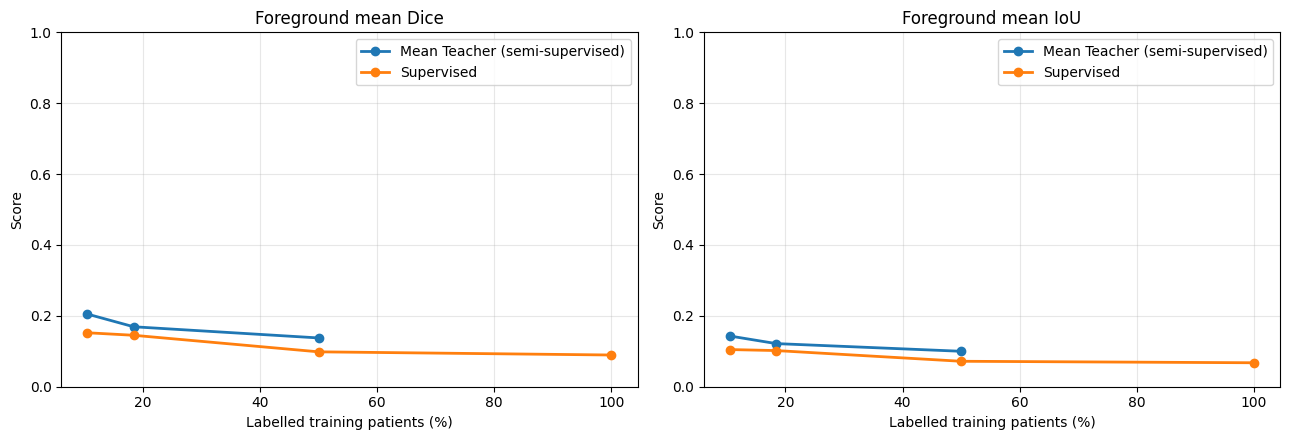

method,nominal_label_fraction,Mean Teacher (semi-supervised),Supervised,MT_minus_supervised_Dice
0,0.1,0.204915,0.152248,0.052667
1,0.2,0.169181,0.145163,0.024018
2,0.5,0.137660,0.098456,0.039204
3,1.0,NaN,0.089492,NaN


Saved results to: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_label_budget_comparison


In [19]:
plot_metrics = ['mean_dice_foreground', 'mean_iou_foreground']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in zip(axes, plot_metrics, ['Foreground mean Dice', 'Foreground mean IoU']):
    for method, group in summary_df.groupby('method'):
        group = group.sort_values('actual_label_fraction')
        ax.plot(group['actual_label_fraction']*100, group[metric], marker='o', linewidth=2, label=method)
    ax.set_title(title); ax.set_xlabel('Labelled training patients (%)'); ax.set_ylabel('Score')
    ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'ratio_sweep_metrics.png', dpi=160, bbox_inches='tight'); plt.show()

# Direct method differences at each fraction where a Mean Teacher row exists.
wide = summary_df.pivot_table(index='nominal_label_fraction', columns='method', values='mean_dice_foreground', aggfunc='first').reset_index()
if 'Supervised' in wide.columns and 'Mean Teacher (semi-supervised)' in wide.columns:
    wide['MT_minus_supervised_Dice'] = wide['Mean Teacher (semi-supervised)'] - wide['Supervised']
display(wide)
wide.to_csv(OUTPUT_ROOT/'ratio_sweep_method_differences.csv', index=False)
print('Saved results to:', OUTPUT_ROOT)

## 12. Compare 20% predictions on the same validation ROI

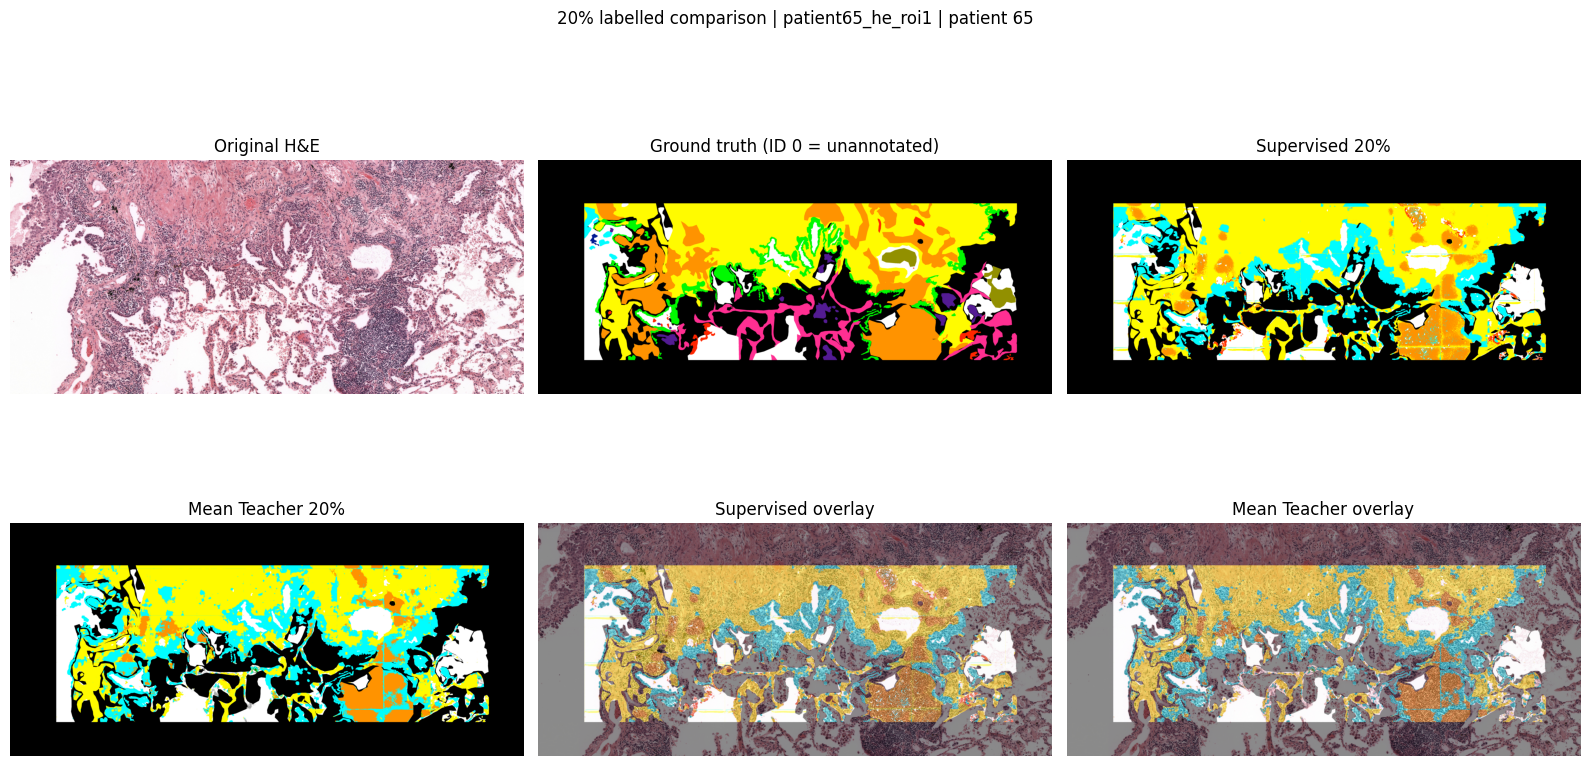

In [20]:
# Visual side-by-side for the 20% experiment, if 20% was included in LABEL_FRACTIONS.
frac = 0.20
if frac not in LABEL_FRACTIONS:
    print('Add 0.20 to LABEL_FRACTIONS and rerun to generate the 20% visual comparison.')
else:
    sup_path = trained_model_paths[(frac, 'supervised')]
    mt_path = trained_model_paths[(frac, 'mean_teacher')]
    sup_ck = torch.load(sup_path, map_location='cpu', weights_only=False)
    mt_ck = torch.load(mt_path, map_location='cpu', weights_only=False)
    sup_model = build_model(pretrained=False).to(DEVICE); sup_model.load_state_dict(sup_ck['model_state_dict']); sup_model.eval()
    mt_model = build_model(pretrained=False).to(DEVICE); mt_model.load_state_dict(mt_ck['model_state_dict']); mt_model.eval()

    PALETTE = np.array([
        [0,0,0], [255,255,255], [0,253,255], [0,249,0], [255,251,0],
        [255,147,0], [255,47,146], [148,55,255], [1,25,147], [255,38,0],
        [0,143,0], [146,144,0], [169,169,169], [83,27,147], [255,126,121],
        [215,131,255], [148,23,81]
    ], dtype=np.uint8)

    @torch.inference_mode()
    def predict_roi(model, image):
        h,w = image.shape[:2]
        pad_h = (PATCH_SIZE-h%PATCH_SIZE)%PATCH_SIZE
        pad_w = (PATCH_SIZE-w%PATCH_SIZE)%PATCH_SIZE
        if pad_h or pad_w:
            mode = 'reflect' if h>1 and w>1 else 'edge'
            image_eval = np.pad(image, ((0,pad_h),(0,pad_w),(0,0)), mode=mode)
        else: image_eval = image
        pred_full = np.zeros(image_eval.shape[:2], dtype=np.uint8)
        for top in range(0,image_eval.shape[0],PATCH_SIZE):
            for left in range(0,image_eval.shape[1],PATCH_SIZE):
                ip = image_eval[top:top+PATCH_SIZE,left:left+PATCH_SIZE]
                x = image_to_tensor(ip).unsqueeze(0).to(DEVICE)
                with autocast_context(): logits = model(x)
                pred_full[top:top+PATCH_SIZE,left:left+PATCH_SIZE] = logits.argmax(1)[0].cpu().numpy().astype(np.uint8)
        return pred_full[:h,:w]

    # Select a validation ROI with many annotated pixels, but never use it for training.
    vis_row = max(val_records, key=lambda r: int(np.count_nonzero(cached_pair(r['resolved_image'],r['resolved_mask'])[1] > IGNORE_INDEX)))
    vis_image, vis_mask, _ = cached_pair(vis_row['resolved_image'], vis_row['resolved_mask'])
    sup_pred = predict_roi(sup_model, vis_image)
    mt_pred = predict_roi(mt_model, vis_image)
    # Mask out unannotated ground-truth regions for visual comparison only.
    sup_vis = sup_pred.copy(); sup_vis[vis_mask == IGNORE_INDEX] = IGNORE_INDEX
    mt_vis = mt_pred.copy(); mt_vis[vis_mask == IGNORE_INDEX] = IGNORE_INDEX

    fig, ax = plt.subplots(2,3,figsize=(16,9))
    ax[0,0].imshow(vis_image); ax[0,0].set_title('Original H&E')
    ax[0,1].imshow(PALETTE[vis_mask]); ax[0,1].set_title('Ground truth (ID 0 = unannotated)')
    ax[0,2].imshow(PALETTE[sup_vis]); ax[0,2].set_title('Supervised 20%')
    ax[1,0].imshow(PALETTE[mt_vis]); ax[1,0].set_title('Mean Teacher 20%')
    ax[1,1].imshow((0.55*vis_image + 0.45*PALETTE[sup_vis]).clip(0,255).astype(np.uint8)); ax[1,1].set_title('Supervised overlay')
    ax[1,2].imshow((0.55*vis_image + 0.45*PALETTE[mt_vis]).clip(0,255).astype(np.uint8)); ax[1,2].set_title('Mean Teacher overlay')
    for a in ax.ravel(): a.axis('off')
    plt.suptitle(f'20% labelled comparison | {vis_row["name"]} | patient {vis_row["patient_id"]}')
    plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'20pct_side_by_side_predictions.png', dpi=160, bbox_inches='tight'); plt.show()
    del sup_model, mt_model; gc.collect(); torch.cuda.empty_cache()

## 13. How to interpret and report the results

Use `ratio_sweep_summary.csv` as the main results table and `ratio_sweep_class_metrics.csv` for tissue-wise results.

- Compare **Supervised** and **Mean Teacher (semi-supervised)** only at the same labelled fraction.
- At 100% labelled data, Mean Teacher is marked N/A because there is no unlabelled training pool.
- The actual fraction is patient-based and may differ slightly from the nominal percentage because patients are indivisible. Your original 20% subset is preserved exactly (7/38 = 18.4%).
- Class-wise NaN means that a class has no ground-truth or prediction support in the validation set under the metric definition; do not silently replace NaN with zero.
- Do not use the official test split for tuning, early stopping, threshold selection, or selecting a model. Once you have finalized the approach, evaluate the selected checkpoint on test data once.

### Epoch recommendation

The default `EPOCHS = 10` is a **pilot** so you can check the complete ratio-sweep pipeline on a free Colab GPU. For a stronger final comparison, set `EPOCHS = 50` and train both methods for the same number of epochs and optimizer updates at the selected label fractions. For the existing 20% Mean Teacher model, the notebook resumes from `last_checkpoint.pth` when you set a higher epoch target. Other fraction-specific Mean Teacher models and supervised controls are trained from scratch or resumed from their own checkpoints.

A 50-epoch run may be interrupted by a free Colab session limit; checkpoints are saved to Drive after every epoch. Resume by rerunning the notebook cells and keeping the same split, fractions, and configuration.